<a href="https://colab.research.google.com/github/alyairawan02/publicdiscussion_analysis/blob/main/Bi_LSTM_TANPA_SMOTE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import random

# Fungsi augmentasi sederhana
def augment_text(text):
    if isinstance(text, str):
        words = text.split()
        if len(words) > 1:
            random.shuffle(words)
        return ' '.join(words)
    return text

In [ ]:
# Data awal
df = pd.read_excel('hasil_labeling_baru.xlsx')

# Hitung jumlah data tiap label
pos_data = df[df['sent_label'].str.upper() == 'POSITIVE']
neg_data = df[df['sent_label'].str.upper() == 'NEGATIVE']

# Target jumlah data per kelas
target = 1500

# Augmentasi POSITIVE
if len(pos_data) < target:
    n_aug_pos = target - len(pos_data)
    aug_pos = pos_data.sample(n=n_aug_pos, replace=True, random_state=42).copy()
    aug_pos['cleaning'] = aug_pos['cleaning'].apply(augment_text)
    aug_pos['sent_label'] = 'POSITIVE'
else:
    aug_pos = pd.DataFrame(columns=df.columns)  # Kosongkan kalau tidak perlu augmentasi

# Augmentasi NEGATIVE
if len(neg_data) < target:
    n_aug_neg = target - len(neg_data)
    aug_neg = neg_data.sample(n=n_aug_neg, replace=True, random_state=42).copy()
    aug_neg['cleaning'] = aug_neg['cleaning'].apply(augment_text)
    aug_neg['sent_label'] = 'NEGATIVE'
else:
    aug_neg = pd.DataFrame(columns=df.columns)  # Kosongkan kalau tidak perlu augmentasi

# Gabungkan semua data
df_final = pd.concat([df, aug_pos, aug_neg], ignore_index=True)

# Cek hasil distribusi
print(df_final['sent_label'].value_counts())
print(f"\n✅ Augmentasi lengkap berhasil. Jumlah data akhir: {len(df_final)}")

sent_label
NEGATIVE    1500
POSITIVE    1500
NEUTRAL     1052
Name: count, dtype: int64

✅ Augmentasi lengkap berhasil. Jumlah data akhir: 4052


In [ ]:
print(df_final['sent_label'].value_counts())

sent_label
NEGATIVE    1500
POSITIVE    1500
NEUTRAL     1052
Name: count, dtype: int64


In [ ]:
!pip install transformers torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 28.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 34.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 38.5 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitlin

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

# Load model IndoBERT Sentiment Analysis
model_name = "crypter70/IndoBERT-Sentiment-Analysis"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Buat pipeline untuk analisis sentimen
sentiment_pipe = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

Device set to use cpu


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


# Encode label (pastikan kolom label bernama 'sent_label')
label_encoder = LabelEncoder()
df_final['encoded_label'] = label_encoder.fit_transform(df_final['sent_label'])

In [ ]:
# Membersihkan kolom 'cleaning' dari NaN atau baris kosong
df_final = df_final[df_final['stemming_data'].notna()]
df_final = df_final[df_final['stemming_data'].str.strip() != '']
df_final.loc[:, 'stemming_data'] = df_final['stemming_data'].astype(str)
df_final = df_final.reset_index(drop=True)

In [ ]:
df_final['stemming_data'] = df_final['stemming_data'].fillna('').astype(str)

In [ ]:
#tokenizing

# Tokenisasi teks
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(df_final['stemming_data'])

sequences = tokenizer.texts_to_sequences(df_final['stemming_data'])

In [ ]:
# Padding
max_len = 50  #  distribusi panjang teks
padded_sequences = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')

In [ ]:
from tensorflow.keras.utils import to_categorical

# One-hot encoding untuk label
onehot_labels = to_categorical(df_final['encoded_label'], num_classes=3)

# 0 → [1. 0. 0.]
# 1 → [0. 1. 0.]
# 2 → [0. 0. 1.]

In [ ]:
#split data (test set & training set)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    padded_sequences, onehot_labels,
    test_size=0.2,
    random_state=42
)

In [ ]:
#visualisasi split data
print("Shape X_train:", X_train.shape)
print("Shape X_test:", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test:", y_test.shape)

Shape X_train: (3241, 50)
Shape X_test: (811, 50)
Shape y_train: (3241, 3)
Shape y_test: (811, 3)


In [ ]:
print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 3241
Jumlah data testing: 811


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 88s 587ms/step - accuracy: 0.3234 - loss: 1.8265 - val_accuracy: 0.4599 - val_loss: 1.5244 - learning_rate: 1.0000e-04
Epoch 2/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 31s 390ms/step - accuracy: 0.3890 - loss: 1.6826 - val_accuracy: 0.4846 - val_loss: 1.5106 - learning_rate: 1.0000e-04
Epoch 3/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 24s 459ms/step - accuracy: 0.4229 - loss: 1.5548 - val_accuracy: 0.5117 - val_loss: 1.4942 - learning_rate: 1.0000e-04
Epoch 4/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 49s 598ms/step - accuracy: 0.4894 - loss: 1.4496 - val_accuracy: 0.5364 - val_loss: 1.4708 - learning_rate: 1.0000e-04
Epoch 5/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 20s 397ms/step - accuracy: 0.5626 - loss: 1.3396 - val_accuracy: 0.5721 - val_loss: 1.4371 - learning_rate: 1.0000e-04
Epoch 6/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 18s 354ms/step - accuracy: 0.5939 - loss: 1.2774 - val_accuracy: 0.5943 - val_loss: 1.3885 - learning_rate: 1.0000e-04
Epoch 7/20
51/51 ━━━━━━━━━━━━━━━━━━━━ 20s 394ms/step - acc

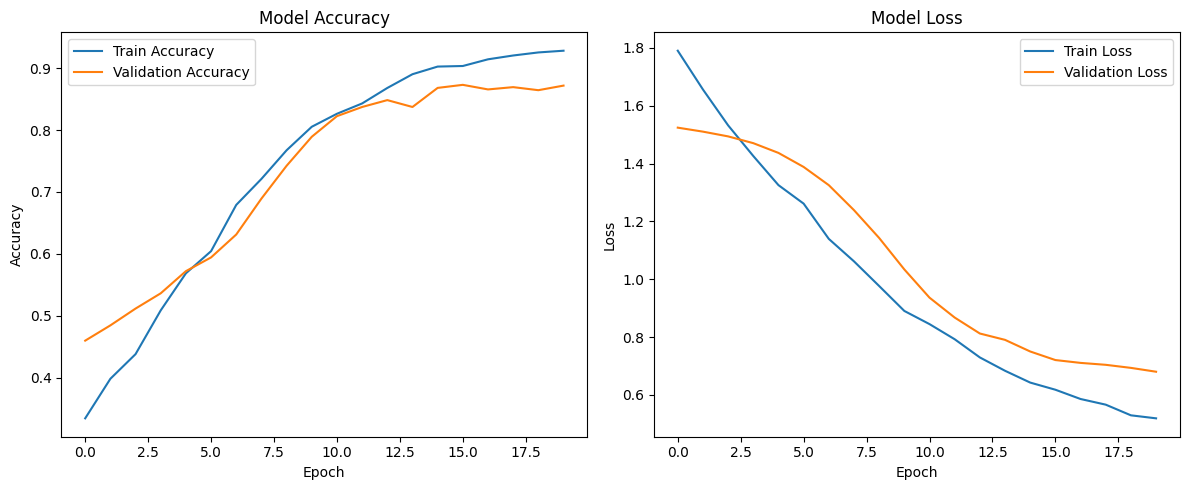

In [ ]:
#LSTM
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import regularizers
from tensorflow.keras.layers import SpatialDropout1D

# Arsitektur model yang diperbaiki
model = Sequential()
model.add(Embedding(input_dim=10000, output_dim=128, input_length=200))  # lebih banyak vocab
model.add(SpatialDropout1D(0.2))

# Stacked Bidirectional LSTM
model.add(Bidirectional(LSTM(64, return_sequences=True, dropout=0.3, recurrent_dropout=0.2)))
model.add(Bidirectional(LSTM(32, return_sequences=False, dropout=0.3, recurrent_dropout=0.2)))
model.add(BatchNormalization())

# Dense layer
model.add(Dense(32, activation='tanh', kernel_regularizer=regularizers.l2(0.01)))
model.add(Dropout(0.4))

# Output layer
model.add(Dense(3, activation='softmax'))  # 3 kelas: negatif, netral, positif

# Compile
model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(learning_rate=1e-4),
    metrics=['accuracy']
)

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)

# Train model (LSTM tanpa SMOTE)
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_test, y_test),
    callbacks=[early_stop, reduce_lr]
)


# Visualisasi hasil
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
#data testing

# Evaluasi ke data test
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.6803
Test Accuracy: 0.8718


30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 113ms/step
              precision    recall  f1-score   support

    Negative       0.87      0.92      0.90       303
     Neutral       0.91      0.76      0.82       202
    Positive       0.92      0.96      0.94       427

    accuracy                           0.90       932
   macro avg       0.90      0.88      0.89       932
weighted avg       0.90      0.90      0.90       932



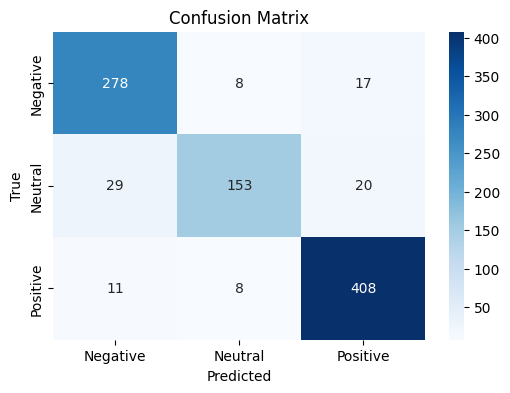

In [ ]:
#confusion matrix
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Prediksi label
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

# Laporan klasifikasi
print(classification_report(y_true, y_pred, target_names=['Negative', 'Neutral', 'Positive']))

# Confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Neutral', 'Positive'],
            yticklabels=['Negative', 'Neutral', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()